# SkillPath: un recomendador de Learning paths de Skills

**Taller de Sistemas Recomendadores, Grupo 7 (Gabriel Escobar y Oscar Ramirez). Parte 2.3: prototipo funcional.**

Este cuaderno cuenta, de punta a punta y paso a paso, cómo funciona el prototipo. Está escrito para alguien que apenas empieza con sistemas recomendadores: cada concepto se explica antes de usarse y casi todas las cifras salen del código que se ejecuta aquí, no están escritas a mano.

## 0. Objetivo y problema

Un **Learner** (estudiante, recién graduado o profesional de TI) quiere trabajar como **Data Analyst**, **Software Engineer** o **Data Scientist**, pero no sabe **qué Skills aprender ni en qué orden**: las **Offers** piden cientos de tecnologías distintas y cada persona parte de conocimientos diferentes. SkillPath recibe un *Learner profile* (Role objetivo, Skills que ya conoce con su *Mastery level* e intereses) y devuelve un **Learning path**: una lista corta y ordenada de Skills por aprender.

### Estrategia híbrida

| Pieza | Qué hace | Dónde se ve en este cuaderno |
|---|---|---|
| **Filtrado basado en contenido** | Convierte cada Skill en un texto corto, lo representa con **TF-IDF** y mide qué tan parecidas son dos Skills con la **similitud del coseno**. Las Skills cercanas a lo que el Learner sabe o le interesa suben. | Sección 5 |
| **Recomendación basada en conocimiento** | Reglas curadas por personas: **Prerequisites** (qué conviene saber antes) y **Difficulty** (de 1 a 5). Con ellas se calcula el **Effort** de cada Skill para *este* Learner y se excluye lo que ya domina. | Sección 6 |
| **Peso por Frequency** | Cuánto aparece cada Skill en las Offers del Role (porcentaje). Lo que el mercado pide más pesa más. | Secciones 1 a 3 y 6 |

La prioridad de cada Skill candidata combina las tres piezas:

$$\text{Prioridad}(s) = \frac{\text{Frequency}(s)\,\times\,\bigl(1 + \text{similitud}(s)\bigr)}{\text{Effort}(s)}$$

**No hay ningún LLM en tiempo de ejecución** (ADR 0003): el sistema es determinista. Con el mismo Learner profile siempre devuelve el mismo Learning path, y cada recomendación se puede explicar con números.

### Cómo leer este cuaderno

1. Las secciones 1 a 4 preparan los *datos*: de dónde salen, cómo se limpian, cuánto pide el mercado y qué Skills tiene el Catalog.
2. La sección 5 explica el **criterio de similitud**, que es el corazón del filtrado basado en contenido.
3. La sección 6 explica las reglas de conocimiento y resuelve una recomendación a mano.
4. La sección 7 muestra recomendaciones para tres Learner profiles distintos.
5. La sección 8 resume la evaluación y los sesgos; la 9, las limitaciones y cómo ejecutar la app.

El cuaderno **reutiliza el paquete `skillpath`**: la lógica del recomendador vive allí (la usa también la app web) y aquí solo se llama y se comprueba. Los pequeños cálculos "a mano" (un ejemplo de TF-IDF de juguete, un Effort explicado) existen solo para enseñar, y cada uno se verifica con `assert` contra el paquete.

In [1]:
# Preparación: localización robusta de carpetas, librerías y estilo de las gráficas.
%matplotlib inline
import os
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")


def find_repo_root(start: Path) -> Path:
    # Sube desde 'start' hasta encontrar pyproject.toml (la raíz del repositorio).
    for folder in [start, *start.parents]:
        if (folder / "pyproject.toml").exists():
            return folder
    raise FileNotFoundError("No se encontró pyproject.toml hacia arriba desde " + str(start))


# SKILLPATH_REPO permite fijar la raíz; si no, se busca desde la carpeta del cuaderno.
REPO = Path(os.environ["SKILLPATH_REPO"]) if os.environ.get("SKILLPATH_REPO") else find_repo_root(Path.cwd().resolve())
# datos/ no se versiona. SKILLPATH_DATOS_DIR permite apuntar a otra carpeta (o a una vacía
# para comprobar que el cuaderno funciona sin los datasets).
DATOS_DIR = Path(os.environ.get("SKILLPATH_DATOS_DIR", REPO / "datos"))
CATALOG_DIR = REPO / "catalog"
REPORTS_DIR = REPO / "reports"

if str(REPO) not in sys.path:  # por si el paquete no está instalado en este entorno
    sys.path.insert(0, str(REPO))

# Paquete del motor: SkillPath se importa, no se reescribe.
from skillpath import LearnerProfile, recommend, catalog, similarity
from skillpath.frequency import normalize_skill, load_aliases, load_exclusions, compute_frequency
from skillpath.cooccurrence import COOCCURRENCE_CSV, load_cooccurrence
from skillpath.recommender import entry_weight, ENTRY_PRIOR_OFFERS, MIN_ENTRY_OFFERS

# Estilo: gráficas estáticas, colores aptos para daltonismo (paleta Okabe-Ito), un color por Role.
ROLE_COLORS = {"Data Analyst": "#0072B2", "Software Engineer": "#E69F00", "Data Scientist": "#009E73"}
INK, MUTED = "#222222", "#6b6b6b"
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e6e6",
    "axes.axisbelow": True, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
})
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 100)

ROLES = catalog.ROLES
print("Raíz del repositorio:", REPO.name)
print("¿Existe datos/?     :", DATOS_DIR.is_dir() and any(DATOS_DIR.iterdir()))
print("Roles               :", ROLES)
print("Skills en el Catalog:", len(catalog.CATALOG))

Raíz del repositorio: recomendadores
¿Existe datos/?     : True
Roles               : ['Data Analyst', 'Software Engineer', 'Data Scientist']
Skills en el Catalog: 64


## 1. Datos y fuentes

SkillPath usa **datasets reales de Offers de LinkedIn publicados en Kaggle**. Los archivos pesan cientos de MB y **no se versionan** en el repositorio (`datos/`); lo que sí se versiona son los resultados ya calculados (`catalog/` y `reports/`). Por eso este cuaderno funciona sin `datos/`: solo la vista previa de datos crudos la necesita.

| Dataset | Enlace (Kaggle) | Papel en SkillPath | Columnas usadas |
|---|---|---|---|
| **asaniczka: Data Analyst Job Postings** | <https://www.kaggle.com/datasets/asaniczka/data-analyst-job-postings> | **Base** de la Frequency y la co-ocurrencia del Role Data Analyst (un dataset = un Role) | `job_skills` (y `job_summary` solo para calibrar el detector de texto) |
| **asaniczka: Software Engineer Job Postings** | <https://www.kaggle.com/datasets/asaniczka/software-engineer-job-postings-linkedin> | **Base** para Software Engineer | igual |
| **asaniczka: Data Scientist Job Postings** | <https://www.kaggle.com/datasets/asaniczka/data-scientist-linkedin-job-postings> | **Base** para Data Scientist | igual |
| **arshkon: LinkedIn Job Postings (2023-2024)** | <https://www.kaggle.com/datasets/arshkon/linkedin-job-postings> | **Complemento de nivel inicial** (Entry level + Internship): sus "habilidades" son categorías amplias, así que las Skills del Catalog se detectan en el texto de la descripción (ADR 0002) | `title`, `description`, `formatted_experience_level` |
| **rajatraj0502: LinkedIn Job 2023** | <https://www.kaggle.com/datasets/rajatraj0502/linkedin-job-2023> | **Descargado pero no usado**: según el ADR 0002, "tiene el mismo problema de categorías amplias" que arshkon (y, a diferencia de este, no aportaba nada que lo justificara) | ninguna |

> **Licencia y términos de uso.** Cada dataset tiene su propia licencia y términos en su página de Kaggle; hay que revisarlos antes de redistribuir o reutilizar los datos. Aquí solo se versionan cifras agregadas (porcentajes y conteos), nunca las Offers originales.

### Tamaños de muestra (de los artefactos versionados)

In [2]:
# Tamaños de muestra por Role, leídos de los CSV versionados (no de datos/).
base = pd.read_csv(CATALOG_DIR / "frequency_by_role.csv")
entry = pd.read_csv(CATALOG_DIR / "frequency_entry_by_role.csv")
part = pd.read_csv(REPORTS_DIR / "partition_summary.csv").set_index("role")

sizes = pd.DataFrame({
    "Offers en el dataset (asaniczka)": part["offers_total"],
    "Offers con job_skills (denominador de la Frequency)": base.groupby("role")["role_offers"].first(),
    "Offers de nivel inicial (arshkon, tras deduplicar)": entry.groupby("role")["role_offers"].first(),
}).loc[ROLES]
sizes["Peso w del nivel inicial"] = [round(entry_weight(int(n)), 2) for n in sizes.iloc[:, 2]]
sizes.index.name = "Role"
display(sizes)
print("Skills distintas en la tabla de Frequency base:", base["skill"].nunique(),
      "| filas de la tabla:", len(base))

,Offers en el dataset (asaniczka),Offers con job_skills (denominador de la Frequency),"Offers de nivel inicial (arshkon, tras deduplicar)",Peso w del nivel inicial
Role,,,,
Data Analyst,12894,12705,80,0.44
Software Engineer,9380,9367,216,0.68
Data Scientist,4342,4336,47,0.32


Skills distintas en la tabla de Frequency base: 425 | filas de la tabla: 669


**Cómo leer la tabla.** La Frequency base se calcula sobre las Offers que traen el campo `job_skills` no vacío (la segunda columna). Las Offers de nivel inicial de arshkon son pocas (decenas a unos cientos), por eso solo *complementan* a la base y se mezclan con un peso `w` pequeño (sección 7).

### Vista previa de los datos crudos (solo si existe `datos/`)

La celda siguiente lee **pocas filas** (`nrows`) y **solo las columnas necesarias**. Nunca se carga arshkon completo (pesa unos 500 MB). Si `datos/` no existe, la celda se omite con un aviso y el resto del cuaderno no cambia.

In [3]:
# Vista previa de datos crudos: solo con datos/ presente; pocas filas y pocas columnas.
asaniczka_da = DATOS_DIR / "asaniczka_data-analyst-job-postings" / "postings.csv"
arshkon_csv = DATOS_DIR / "arshkon_linkedin-job-postings" / "postings.csv"

if asaniczka_da.exists():
    preview = pd.read_csv(asaniczka_da, usecols=["job_title", "job level", "job_skills"], nrows=2000)
    preview = preview[preview["job_skills"].notna()].head(3)
    print("asaniczka (Data Analyst): 3 Offers con job_skills, de las primeras 2.000 filas")
    display(preview.assign(job_skills=preview["job_skills"].str.slice(0, 160) + "..."))
else:
    print("OMITIDO: no existe", asaniczka_da.name, "(sin datos/ no hay vista previa de asaniczka).")

if arshkon_csv.exists():
    # usecols + nrows: no se carga el archivo completo; la descripción se recorta a 160 caracteres.
    prev2 = pd.read_csv(arshkon_csv, usecols=["title", "formatted_experience_level", "description"], nrows=3)
    prev2["description"] = prev2["description"].str.slice(0, 160) + "..."
    print("arshkon: 3 primeras filas (3 columnas)")
    display(prev2)
else:
    print("OMITIDO: no existe", arshkon_csv.name, "(sin datos/ no hay vista previa de arshkon).")

asaniczka (Data Analyst): 3 Offers con job_skills, de las primeras 2.000 filas


,job_title,job level,job_skills
1,Market Research & Insights Analyst,Mid senior,"Data analysis, Market research, Survey development, Analytical methods, Quantitative initiatives, Qualitative initiatives, Business solutions, Project managemen..."
2,Business Systems Analyst `1,Mid senior,"Business Analysis, Technical Writing, Software Testing, Systems Development, Process Improvement, SDLC, Web Technologies, JBASE, Mobile Technologies, Relational..."
3,Senior VAT and Indirect Tax Analyst,Mid senior,"Accounting, Finance, VAT/GST tax regimes, US and foreign tax laws, VAT and sales tax issues, Indirect tax, Sales and use tax, Excise tax, Tax compliance, Tax au..."


arshkon: 3 primeras filas (3 columnas)


,title,description,formatted_experience_level
0,Marketing Coordinator,Job descriptionA leading real estate firm in New Jersey is seeking an administrative Marketing Coordinator with some experience in graphic design. You will be w...,NaN
1,Mental Health Therapist/Counselor,"At Aspen Therapy and Wellness , we are committed to serving clients with best practices to help them with change, improvements and better quality of life. We be...",NaN
2,Assitant Restaurant Manager,"The National Exemplar is accepting applications for an Assistant Restaurant Manager.\nWe offer highly competitive wages, healthcare, paid time off, complimentary...",NaN


## 2. Normalización: alias y exclusiones

Los datasets traen decenas de miles de textos distintos en el campo `job_skills`: `Python`, `python3`, `Python 3`, `Communication`... Antes de contar hay que **normalizar**:

1. **Normalizar el texto:** minúsculas, espacios colapsados y puntuación de borde eliminada.
2. **Aplicar alias** (`catalog/aliases.csv`): variantes de una misma Skill pasan a su nombre canónico (`python3` pasa a `python`). Un solo paso, sin encadenar.
3. **Descartar exclusiones** (`catalog/exclusions.txt`): habilidades blandas y términos genéricos no técnicos (`communication`, `teamwork`...).

Ejemplos reales del repositorio, con la función `normalize_skill` del paquete:

In [4]:
aliases = load_aliases(catalog_aliases := CATALOG_DIR / "aliases.csv")
exclusions = load_exclusions(CATALOG_DIR / "exclusions.txt")
print(f"{len(aliases)} alias y {len(exclusions)} exclusiones en el repositorio.\n")

# Primeros alias del archivo, tal cual están escritos.
raw_aliases = pd.read_csv(catalog_aliases)
display(raw_aliases.sample(10, random_state=0).sort_index().reset_index(drop=True))

# Pasos de la normalización sobre textos "sucios" (el primer paso lo hace normalize_skill).
raw_examples = ["Python3", "  SQL ", "Machine Learning.", "Communication", "Teamwork", "Tableau", "ML"]
rows = []
for raw in raw_examples:
    norm = normalize_skill(raw, aliases)
    rows.append({"texto original": repr(raw), "normalizado + alias": norm,
                 "¿excluida?": "sí" if norm in exclusions else "no",
                 "¿está en el Catalog?": "sí" if norm in catalog.CATALOG else "no"})
display(pd.DataFrame(rows))

80 alias y 46 exclusiones en el repositorio.



,alias,skill
0,postgres,postgresql
1,microsoft sql server,sql server
2,restful api,rest api
3,rest,rest api
4,html5,html
5,tensorflow 2,tensorflow
6,verbal communication,communication
7,written communication,communication
8,problemsolving,problem solving
9,analytical thinking,analytical skills


,texto original,normalizado + alias,¿excluida?,¿está en el Catalog?
0,'Python3',python,no,sí
1,' SQL ',sql,no,sí
2,'Machine Learning.',machine learning,no,sí
3,'Communication',communication,sí,no
4,'Teamwork',teamwork,sí,no
5,'Tableau',tableau,no,sí
6,'ML',machine learning,no,sí


### Cómo se calcula la Frequency (con tres Offers de juguete)

**Frequency = 100 × (Offers del Role que mencionan la Skill) / (Offers del Role con `job_skills` no vacío).** Cada Offer cuenta una sola vez por Skill, aunque repita variantes. El paquete tiene la función pura `compute_frequency`; la usamos con tres Offers inventadas para ver el efecto de los alias y las exclusiones:

In [5]:
toy_offers = {"Role de juguete": [
    "Python3, SQL, Communication, Tableau",   # python3 -> python; communication se excluye
    "python, Teamwork, sql",                  # teamwork se excluye
    "Excel, python 3",                        # python 3 -> python
    "",                                       # sin job_skills: no entra al denominador
]}
toy = compute_frequency(toy_offers, aliases, exclusions)
display(toy)
assert toy.loc[toy.skill == "python", "frequency"].iloc[0] == 100.0   # 3 de 3 Offers con job_skills

,role,skill,offers_with_skill,role_offers,frequency
0,Role de juguete,python,3,3,100.000000
1,Role de juguete,sql,2,3,66.666667
2,Role de juguete,excel,1,3,33.333333
3,Role de juguete,tableau,1,3,33.333333


## 3. Frequency por Role

La Frequency base está en `catalog/frequency_by_role.csv` (se genera con `python -m skillpath.build_frequency` cuando se tiene `datos/`). El paquete la carga en `catalog.FREQUENCY[role][skill]`. Veamos las 10 Skills **del Catalog** más frecuentes de cada Role:

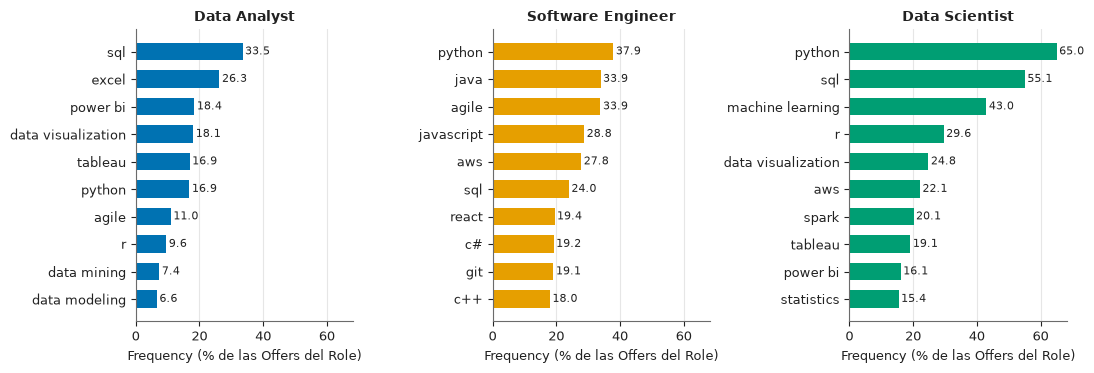

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), sharex=True)
for ax, role in zip(axes, ROLES):
    freq = {s: catalog.FREQUENCY[role].get(normalize_skill(s, catalog.ALIASES), 0.0) for s in catalog.CATALOG}
    top = pd.Series(freq).sort_values(ascending=False).head(10)[::-1]
    ax.barh(top.index, top.values, color=ROLE_COLORS[role], height=0.65)
    for y, v in enumerate(top.values):
        ax.text(v + 0.8, y, f"{v:.1f}", va="center", fontsize=8, color=INK)
    ax.set_title(role)
    ax.set_xlabel("Frequency (% de las Offers del Role)")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Qué se ve.** Cada Role pide un conjunto distinto: `sql` y `excel` dominan en Data Analyst, `python`, `java` y `agile` en Software Engineer, `python`, `sql` y `machine learning` en Data Scientist. Frequency mide cuánto *aparece* una Skill, no cuánto cuesta aprenderla ni cuánto le conviene a una persona concreta; por eso la Frequency sola no basta y hace falta el Effort.

## 4. El Catalog de Skills

Recomendar cualquier texto que aparezca en `job_skills` no sirve: es ruidoso y no trae atributos para razonar sobre el esfuerzo (ADR 0001). Por eso el **Catalog** es un conjunto *curado* de Skills técnicas (`catalog/skills.csv`), cada una con **categoría, descripción, Difficulty (1 a 5) y Prerequisites**. Difficulty y Prerequisites son *juicio experto*, redactado por un agente y revisado por personas; no son un dato observado en las Offers.

In [7]:
cat_df = pd.DataFrame([
    {"Skill": s.name, "Categoría": s.category, "Difficulty": s.difficulty,
     "Prerequisites": ", ".join(s.prerequisites) if s.prerequisites else "-"}
    for s in catalog.CATALOG.values()
]).sort_values(["Categoría", "Difficulty", "Skill"]).reset_index(drop=True)
print(f"{len(cat_df)} Skills en {cat_df['Categoría'].nunique()} categorías; "
      f"{(cat_df['Prerequisites'] != '-').sum()} tienen al menos un Prerequisite.")
display(cat_df)

64 Skills en 11 categorías; 40 tienen al menos un Prerequisite.


,Skill,Categoría,Difficulty,Prerequisites
0,ci/cd,DevOps,3,git
1,docker,DevOps,3,linux
2,kubernetes,DevOps,4,docker
3,data cleaning,análisis de datos,2,-
4,excel,análisis de datos,2,-
5,a/b testing,análisis de datos,3,statistics
6,data mining,análisis de datos,3,"statistics, sql"
7,numpy,análisis de datos,3,python
8,pandas,análisis de datos,3,python
9,sas,análisis de datos,3,-


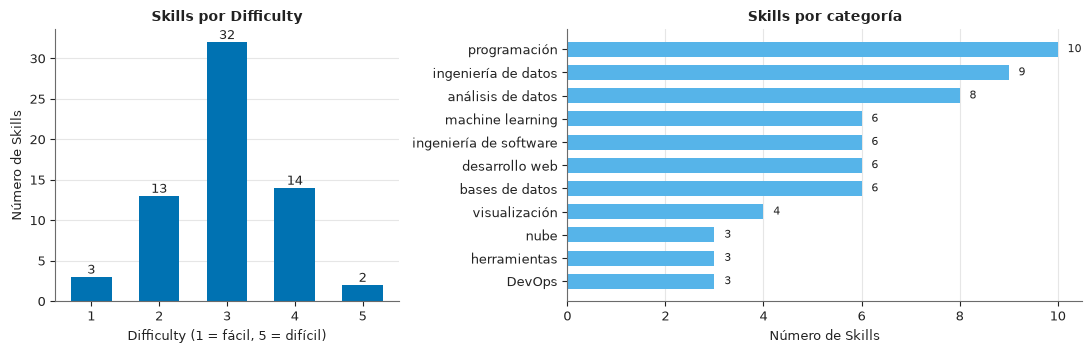

In [8]:
# Distribución de Difficulty y número de Skills por categoría.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1.5]})
diff_counts = cat_df["Difficulty"].value_counts().reindex(range(1, 6), fill_value=0)
ax1.bar(diff_counts.index, diff_counts.values, color="#0072B2", width=0.6)
for x, v in diff_counts.items():
    ax1.text(x, v + 0.4, str(v), ha="center", fontsize=9)
ax1.set_xlabel("Difficulty (1 = fácil, 5 = difícil)")
ax1.set_ylabel("Número de Skills")
ax1.set_title("Skills por Difficulty")
ax1.grid(axis="x", visible=False)

cat_counts = cat_df["Categoría"].value_counts().sort_values()
ax2.barh(cat_counts.index, cat_counts.values, color="#56B4E9", height=0.65)
for y, v in enumerate(cat_counts.values):
    ax2.text(v + 0.2, y, str(v), va="center", fontsize=8)
ax2.set_xlabel("Número de Skills")
ax2.set_title("Skills por categoría")
ax2.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### Prerequisites: el grafo del Catalog

Un **Prerequisite** es una Skill del propio Catalog que conviene saber antes de otra (solo los directos; los transitivos salen de encadenar). No hay ciclos. El siguiente diagrama coloca cada Skill en una columna según la longitud de su cadena de Prerequisites (columna 0 = no necesita nada) y dibuja una flecha de cada Prerequisite a la Skill que lo necesita. Solo aparecen las Skills que participan en alguna relación.

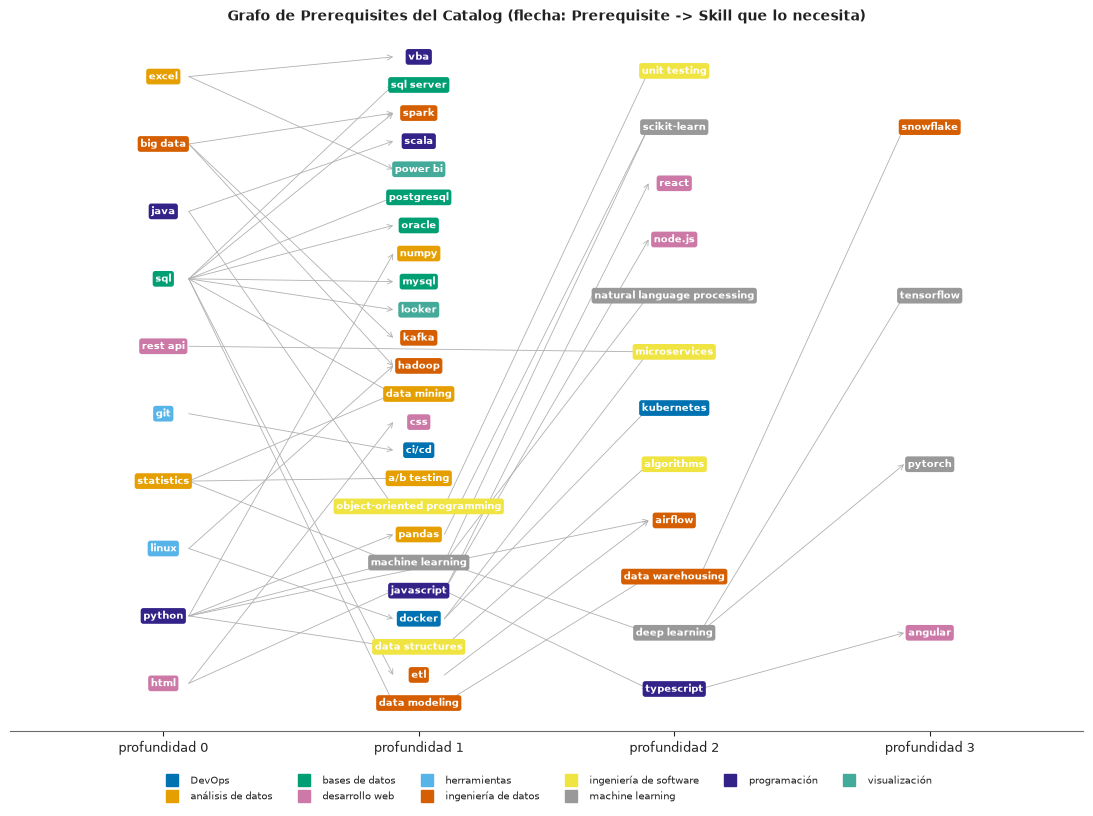

Cadena profunda ejemplo:
  python             Difficulty 2  Prerequisites: -
  statistics         Difficulty 3  Prerequisites: -
  machine learning   Difficulty 4  Prerequisites: python, statistics
  deep learning      Difficulty 5  Prerequisites: machine learning
  tensorflow         Difficulty 4  Prerequisites: deep learning


In [9]:
# Profundidad de cada Skill = longitud de su cadena más larga de Prerequisites.
skills = catalog.CATALOG
depth = {}
def get_depth(name):
    if name not in depth:
        pre = skills[name].prerequisites
        depth[name] = 0 if not pre else 1 + max(get_depth(p) for p in pre)
    return depth[name]
for n in skills:
    get_depth(n)

edges = [(p, s.name) for s in skills.values() for p in s.prerequisites]
involved = sorted({a for a, b in edges} | {b for a, b in edges})
columns = {}
for n in involved:
    columns.setdefault(depth[n], []).append(n)
# Orden vertical: se reduce el cruce de flechas ordenando cada columna por la posición
# media de sus vecinos (barrido hacia delante y hacia atrás), y se reparte parejo en vertical.
parents = {n: list(skills[n].prerequisites) for n in involved}
children = {n: [b for a, b in edges if a == n] for n in involved}
height = max(len(v) for v in columns.values())
ypos = {}


def place(d):
    for i, n in enumerate(columns[d]):
        ypos[n] = -(i + 0.5) * height / len(columns[d])


for d in columns:
    columns[d].sort(key=lambda n: (skills[n].category, n))
    place(d)
for sweep in range(4):
    for d in sorted(columns)[1:]:
        columns[d].sort(key=lambda n: (sum(ypos[p] for p in parents[n]) / len(parents[n]), n), reverse=True)
        place(d)
    for d in sorted(columns, reverse=True)[1:]:
        columns[d].sort(key=lambda n: (sum(ypos[c] for c in children[n]) / len(children[n]) if children[n] else 0, n), reverse=True)
        place(d)
pos = {n: (d, ypos[n]) for d, names in columns.items() for n in names}

cat_palette = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00", "#F0E442",
               "#999999", "#332288", "#44AA99", "#AA4499"]
cats = sorted({skills[n].category for n in involved})
cat_color = {c: cat_palette[i % len(cat_palette)] for i, c in enumerate(cats)}

fig, ax = plt.subplots(figsize=(11, 8.2))
for a, b in edges:
    (x1, y1), (x2, y2) = pos[a], pos[b]
    ax.annotate("", xy=(x2 - 0.1, y2), xytext=(x1 + 0.1, y1), zorder=1,
                arrowprops=dict(arrowstyle="->", color="#b0b0b0", lw=0.6, shrinkA=0, shrinkB=0))
for n, (x, y) in pos.items():
    ax.text(x, y, n, ha="center", va="center", fontsize=7.5, color="white", fontweight="bold", zorder=3,
            bbox=dict(boxstyle="round,pad=0.25", fc=cat_color[skills[n].category], ec="none"))
ax.set_xlim(-0.6, max(columns) + 0.6)
ax.set_ylim(-height - 0.5, 0.5)
ax.set_xticks(sorted(columns))
ax.set_xticklabels([f"profundidad {d}" for d in sorted(columns)])
ax.set_yticks([])
ax.grid(False)
ax.spines["left"].set_visible(False)
handles = [plt.Line2D([0], [0], marker="s", ls="", color=cat_color[c], label=c, markersize=8) for c in cats]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.05), ncol=6, fontsize=7.5, frameon=False)
ax.set_title("Grafo de Prerequisites del Catalog (flecha: Prerequisite -> Skill que lo necesita)")
plt.tight_layout()
plt.show()

chain = ["python", "statistics", "machine learning", "deep learning", "tensorflow"]
print("Cadena profunda ejemplo:")
for n in chain:
    print(f"  {n:18s} Difficulty {skills[n].difficulty}  Prerequisites: {', '.join(skills[n].prerequisites) or '-'}")

## 5. Criterio de similitud (el corazón del filtrado basado en contenido)

> **Pregunta que responde esta sección:** ¿cuándo decimos que dos Skills "se parecen", y cómo usamos esa cercanía para recomendar?

**Idea en una frase.** Cada Skill del Catalog se convierte en un *texto corto*; dos Skills se parecen si sus textos comparten palabras importantes. Un Learner se resume con el mismo tipo de vector (su *ancla*), y las Skills candidatas más parecidas al ancla suben en el Learning path.

La similitud se calcula **por Role**: la cercanía entre Skills depende del mercado de cada Role, y el Learner siempre tiene un Role objetivo. El modelo (`similarity.get_model(role)`) se ajusta solo con los textos de las 64 Skills, sin datos externos, sin azar y sin embeddings ni LLM.

### 5.1 Qué texto se construye de cada Skill

Cada Skill se representa con un *documento* formado por estas piezas (los números de repetición son constantes del paquete, `skillpath.similarity`):

In [10]:
S = similarity
pieces = pd.DataFrame([
    ["Su propio nombre como una sola palabra (`machine learning` -> `machine_learning`)", S.OWN_NAME_REPEATS, "Que otras Skills que la mencionan se le parezcan."],
    ["Su categoría (`cat_programación`)", S.CATEGORY_REPEATS, "Señal gruesa de \"mismo tipo de Skill\"."],
    ["La descripción del Catalog (sin palabras vacías en español)", 1, "Qué es la Skill. Cada palabra cuenta una vez por aparición."],
    ["Nombres de otras Skills del Catalog mencionadas en la descripción", f"{S.MENTION_EXTRA_REPEATS} copias extra", "Es una relación escrita por quien curó el Catalog."],
    [f"Sus {S.TOP_K_NEIGHBOURS} Skills más cercanas por co-ocurrencia en las Offers del Role", f"1 a {S.NEIGHBOUR_REPEATS}, según la cercanía", "Qué Skills pide el mercado junto con ella."],
], columns=["Pieza del documento", "Veces que entra", "Para qué"])
display(pieces)

,Pieza del documento,Veces que entra,Para qué
0,Su propio nombre como una sola palabra (`machine learning` -> `machine_learning`),3,Que otras Skills que la mencionan se le parezcan.
1,Su categoría (`cat_programación`),2,"Señal gruesa de ""mismo tipo de Skill""."
2,La descripción del Catalog (sin palabras vacías en español),1,Qué es la Skill. Cada palabra cuenta una vez por aparición.
3,Nombres de otras Skills del Catalog mencionadas en la descripción,2 copias extra,Es una relación escrita por quien curó el Catalog.
4,Sus 8 Skills más cercanas por co-ocurrencia en las Offers del Role,"1 a 4, según la cercanía",Qué Skills pide el mercado junto con ella.


La **co-ocurrencia** sale de `catalog/cooccurrence.csv`: para cada Role y cada par de Skills, en cuántas Offers aparecen juntas. La *cercanía* es `offers_juntas / raíz(offers_a × offers_b)` (coeficiente de Ochiai, entre 0 y 1). Es lo que aporta "lo que pide el mercado junto con esta Skill".

Veamos el documento real de `pandas` en el Role Data Scientist (el atributo `documents` del modelo es una vista de solo lectura):

In [11]:
ds_model = similarity.get_model("Data Scientist")
doc = ds_model.documents["pandas"]
print("DOCUMENTO DE 'pandas' (Data Scientist):\n")
print(doc)
print(f"\nEl modelo tiene {ds_model.matrix.shape[0]} documentos (Skills) y {ds_model.matrix.shape[1]} palabras distintas.")

# Las palabras con más peso en el vector TF-IDF de pandas.
features = ds_model.vectorizer.get_feature_names_out()
vec = ds_model.vector("pandas")
top_terms = pd.Series(vec, index=features).sort_values(ascending=False).head(8)
display(top_terms.round(3).rename("peso TF-IDF").to_frame())

DOCUMENTO DE 'pandas' (Data Scientist):

pandas pandas pandas cat_análisis_de_datos cat_análisis_de_datos Biblioteca de Python para cargar, limpiar, transformar y analizar datos tabulares con DataFrames. python python numpy numpy numpy numpy scikit-learn scikit-learn scikit-learn git git python python machine_learning machine_learning tensorflow tensorflow natural_language_processing natural_language_processing docker docker

El modelo tiene 64 documentos (Skills) y 153 palabras distintas.


,peso TF-IDF
numpy,0.543
pandas,0.408
scikit-learn,0.389
python,0.254
cat_análisis_de_datos,0.239
natural_language_processing,0.239
tensorflow,0.239
git,0.198


Arriba se ve cómo `pandas` queda definida por su nombre, su categoría, las palabras de su descripción, `python` (mencionada en su descripción y vecina en las Offers) y otras Skills que el mercado pide junto con ella (`numpy`, `scikit-learn`...). Los nombres de varias palabras se convierten en una sola (`machine_learning`) para que `machine` y `learning` no se separen y se confundan con otras palabras.

### 5.2 Qué es TF-IDF, explicado desde cero

Un computador no entiende textos, entiende números. **TF-IDF** convierte cada documento en una lista de números, un peso por palabra:

* **TF** (*term frequency*): cuántas veces aparece la palabra *en ese documento*. Más apariciones, más peso.
* **IDF** (*inverse document frequency*): qué tan *rara* es la palabra entre *todos* los documentos. Una palabra que está en casi todos (por ejemplo `datos`) no distingue nada y pesa poco; una palabra que está en pocos distingue mucho y pesa más. Con la variante suave de scikit-learn: `IDF = ln((1 + N) / (1 + df)) + 1`, donde `N` es el número de documentos y `df` en cuántos aparece la palabra.
* **Peso = TF × IDF**, y luego el vector se normaliza para que su longitud sea 1 (así los documentos largos no ganan solo por ser largos).

**Ejemplo de juguete con cuatro Skills inventadas** (las repeticiones imitan el documento real: el nombre se repite):

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer

toy_docs = {
    "A: pandas": "pandas pandas python datos datos tablas",
    "B: numpy":  "numpy numpy python datos datos matrices",
    "C: tableau": "tableau tableau datos datos gráficos",
    "D: sql":    "sql sql datos datos consultas",
}
names = list(toy_docs)
tokens = [d.split() for d in toy_docs.values()]
vocab = sorted({w for t in tokens for w in t})
N = len(tokens)

# --- A mano con numpy: TF (conteo), IDF suave, producto y normalización L2 ---
tf = np.array([[t.count(w) for w in vocab] for t in tokens], dtype=float)
df_counts = (tf > 0).sum(axis=0)                  # en cuántos documentos aparece cada palabra
idf = np.log((1 + N) / (1 + df_counts)) + 1
w = tf * idf
w = w / np.linalg.norm(w, axis=1, keepdims=True)  # longitud 1

table = pd.DataFrame(w, index=names, columns=vocab).round(3)
display(Markdown("**Pesos TF-IDF (a mano).** Compárese la columna `datos` (aparece en los 4 documentos, IDF mínimo) con `pandas` o `tableau` (aparecen en uno solo):"))
display(table)
display(Markdown("IDF por palabra: " + ", ".join(f"`{v}` = {i:.2f}" for v, i in zip(vocab, idf))))

# --- Comprobación: scikit-learn da exactamente lo mismo ---
sk = TfidfVectorizer(token_pattern=r"\S+", norm="l2")
sk_matrix = sk.fit_transform(list(toy_docs.values())).toarray()
assert list(sk.get_feature_names_out()) == vocab
assert np.allclose(sk_matrix, w), "El cálculo a mano debe coincidir con scikit-learn"
print("Comprobado: el TF-IDF a mano coincide con TfidfVectorizer.")

**Pesos TF-IDF (a mano).** Compárese la columna `datos` (aparece en los 4 documentos, IDF mínimo) con `pandas` o `tableau` (aparecen en uno solo):

,consultas,datos,gráficos,matrices,numpy,pandas,python,sql,tablas,tableau
A: pandas,0.000,0.403,0.000,0.000,0.000,0.772,0.304,0.00,0.386,0.00
B: numpy,0.000,0.403,0.000,0.386,0.772,0.000,0.304,0.00,0.000,0.00
C: tableau,0.000,0.423,0.405,0.000,0.000,0.000,0.000,0.00,0.000,0.81
D: sql,0.405,0.423,0.000,0.000,0.000,0.000,0.000,0.81,0.000,0.00


IDF por palabra: `consultas` = 1.92, `datos` = 1.00, `gráficos` = 1.92, `matrices` = 1.92, `numpy` = 1.92, `pandas` = 1.92, `python` = 1.51, `sql` = 1.92, `tablas` = 1.92, `tableau` = 1.92

Comprobado: el TF-IDF a mano coincide con TfidfVectorizer.


### 5.3 Qué es la similitud del coseno

Cada documento es ahora un punto (una flecha desde el origen) en un espacio con una dimensión por palabra. La **similitud del coseno** es el coseno del ángulo entre las dos flechas:

* **1** si apuntan en la misma dirección (mismas palabras con pesos proporcionales);
* **0** si no comparten ninguna palabra (flechas perpendiculares).

Como los pesos nunca son negativos, el resultado queda siempre en **[0, 1]**. Si los vectores ya tienen longitud 1 (como los de TF-IDF normalizado), el coseno es simplemente su **producto punto**: `cos(a, b) = a · b`. Solo cuentan las palabras que comparten, ponderadas por su peso.

In [13]:
# Coseno del juguete = producto punto de los vectores normalizados.
cos = w @ w.T
display(pd.DataFrame(cos, index=names, columns=names).round(3))

# El coseno A-B solo suma lo que comparten: python y datos (pandas/numpy no son compartidas).
shared = {vocab[j]: float(w[0, j] * w[1, j]) for j in range(len(vocab)) if w[0, j] > 0 and w[1, j] > 0}
print("Palabras compartidas entre A (pandas) y B (numpy) y su aporte al coseno:", {k: round(v, 3) for k, v in shared.items()})
print("Suma de aportes =", round(sum(shared.values()), 3), "= coseno A-B =", round(cos[0, 1], 3))
assert abs(sum(shared.values()) - cos[0, 1]) < 1e-9

# A (pandas) se parece más a B (numpy, comparte `python`) que a C (tableau, solo comparte `datos`).
assert cos[0, 1] > cos[0, 2] and cos[0, 1] > cos[0, 3]

,A: pandas,B: numpy,C: tableau,D: sql
A: pandas,1.000,0.255,0.170,0.170
B: numpy,0.255,1.000,0.170,0.170
C: tableau,0.170,0.170,1.000,0.179
D: sql,0.170,0.170,0.179,1.000


Palabras compartidas entre A (pandas) y B (numpy) y su aporte al coseno: {'datos': 0.162, 'python': 0.093}
Suma de aportes = 0.255 = coseno A-B = 0.255


**Lectura.** `pandas` y `numpy` comparten `python` y `datos`, así que su coseno es mayor que el de `pandas` con `tableau` o `sql`, que solo comparten la palabra `datos` (que pesa poco porque está en todos los documentos). Eso es exactamente lo que hace el modelo real, pero con 64 documentos y unas 150 palabras por Role.

### 5.4 Resultados reales: las Skills más cercanas a `python` y a `sql`

Para cada Role, el coseno entre el vector de `python` (o `sql`) y el de cada otra Skill del Catalog, obtenido del modelo del paquete (`get_model(role).vector(skill)`). Se muestran también la cercanía directa por co-ocurrencia y las palabras que más aportan al coseno:

In [14]:
cooc = load_cooccurrence(COOCCURRENCE_CSV)   # role -> skill -> {otra skill: cercanía}


def closest(role, skill, k=5):
    # Las k Skills más cercanas a 'skill' en el modelo de 'role', con su coseno real.
    model = similarity.get_model(role)
    v = model.vector(skill)
    feats = model.vectorizer.get_feature_names_out()
    rows = []
    for other in model.names:
        if other == skill:
            continue
        ov = model.vector(other)
        contrib = pd.Series(v * ov, index=feats).sort_values(ascending=False)
        rows.append({
            "Skill": other,
            "Coseno": float(v @ ov),
            "Cercanía por co-ocurrencia": cooc.get(role, {}).get(skill, {}).get(other, 0.0),
            "Palabras que más aportan": ", ".join(f"`{t}`" for t in contrib.index[:3]),
        })
    out = pd.DataFrame(rows).sort_values("Coseno", ascending=False).head(k).reset_index(drop=True)
    out.index += 1
    return out


for skill in ("python", "sql"):
    display(Markdown(f"#### Skills más cercanas a `{skill}` en Data Scientist"))
    display(closest("Data Scientist", skill).round(3))

#### Skills más cercanas a `python` en Data Scientist

,Skill,Coseno,Cercanía por co-ocurrencia,Palabras que más aportan
1,statistics,0.699,0.408,"`machine_learning`, `r`, `data_visualization`"
2,sql,0.690,0.738,"`machine_learning`, `r`, `data_visualization`"
3,r,0.659,0.656,"`machine_learning`, `r`, `data_visualization`"
4,a/b testing,0.632,0.231,"`machine_learning`, `r`, `data_visualization`"
5,data visualization,0.564,0.464,"`machine_learning`, `r`, `data_visualization`"


#### Skills más cercanas a `sql` en Data Scientist

,Skill,Coseno,Cercanía por co-ocurrencia,Palabras que más aportan
1,a/b testing,0.691,0.260,"`data_visualization`, `r`, `tableau`"
2,python,0.690,0.738,"`machine_learning`, `r`, `data_visualization`"
3,data visualization,0.629,0.509,"`tableau`, `r`, `power_bi`"
4,looker,0.595,0.168,"`tableau`, `power_bi`, `data_visualization`"
5,statistics,0.567,0.372,"`machine_learning`, `r`, `data_visualization`"


In [15]:
# La cercanía depende del Role: el mismo `python`, tres mercados.
comparison = {}
for role in ROLES:
    for skill in ("python", "sql"):
        top = closest(role, skill, k=5)
        comparison[(skill, role)] = [f"{r.Skill} ({r.Coseno:.2f})" for r in top.itertuples()]
display(pd.DataFrame(comparison, index=range(1, 6)))

,python,sql,python,sql,python,sql
,Data Analyst,Data Analyst,Software Engineer,Software Engineer,Data Scientist,Data Scientist
1,r (0.78),tableau (0.69),java (0.68),nosql (0.73),statistics (0.70),a/b testing (0.69)
2,statistics (0.77),power bi (0.67),agile (0.57),agile (0.64),sql (0.69),python (0.69)
3,sql (0.61),data visualization (0.67),go (0.57),python (0.53),r (0.66),data visualization (0.63)
4,data visualization (0.58),excel (0.62),scala (0.54),aws (0.53),a/b testing (0.63),looker (0.59)
5,a/b testing (0.58),python (0.61),sql (0.53),java (0.50),data visualization (0.56),statistics (0.57)


In [16]:
# Por qué: un ejemplo de lectura con números reales (Data Scientist).
m = similarity.get_model("Data Scientist")
py, sq = m.vector("python"), m.vector("sql")
c_py_sql = float(py @ sq)
c_direct = cooc["Data Scientist"]["python"]["sql"]
contrib = pd.Series(py * sq, index=m.vectorizer.get_feature_names_out()).sort_values(ascending=False)
c_py_ab = float(py @ m.vector("a/b testing"))
c_direct_ab = cooc["Data Scientist"]["python"].get("a/b testing", 0.0)
display(Markdown(
    f"* `python` y `sql` tienen coseno **{c_py_sql:.2f}** y cercanía directa por co-ocurrencia **{c_direct:.3f}**: "
    f"se piden juntas muy a menudo, y además comparten vecinos como " + ", ".join(f"`{t}`" for t in contrib.index[:3]) + ".\n"
    f"* `a/b testing` tiene una cercanía directa baja con `python` (**{c_direct_ab:.3f}**) pero un coseno alto (**{c_py_ab:.2f}**): "
    f"se parecen porque piden junto a ellas *las mismas Skills*, no solo porque co-ocurran entre sí. Por eso el coseno y la cercanía directa no coinciden.\n"
    f"* Efecto secundario a tener presente: las Skills muy frecuentes (`python`, `sql`, `r`, `machine learning`) aparecen como vecinas de casi todo y "
    f"elevan la similitud de fondo entre Skills de datos. La similitud *ordena*, pero no demuestra una relación causal."))

* `python` y `sql` tienen coseno **0.69** y cercanía directa por co-ocurrencia **0.738**: se piden juntas muy a menudo, y además comparten vecinos como `machine_learning`, `r`, `data_visualization`.
* `a/b testing` tiene una cercanía directa baja con `python` (**0.231**) pero un coseno alto (**0.63**): se parecen porque piden junto a ellas *las mismas Skills*, no solo porque co-ocurran entre sí. Por eso el coseno y la cercanía directa no coinciden.
* Efecto secundario a tener presente: las Skills muy frecuentes (`python`, `sql`, `r`, `machine learning`) aparecen como vecinas de casi todo y elevan la similitud de fondo entre Skills de datos. La similitud *ordena*, pero no demuestra una relación causal.

### 5.5 Cómo entra el Learner: la ancla, los Mastery levels y los intereses

La **ancla** del Learner es la **suma de los vectores** de sus elementos, cada uno multiplicado por un peso:

* **Skills conocidas**, según el **Mastery level**: básico, intermedio o avanzado (pesos abajo). Quien domina más una Skill orienta más la recomendación.
* **Intereses**, con peso 1.0 (declarar un interés es una señal explícita).

La **similitud de cada candidata** es el coseno entre su vector y la ancla (entre 0 y 1). Sin ancla (sin Skills ni intereses reconocidos), la similitud vale 0 para todas.

Una Skill conocida en nivel *básico* sigue siendo candidata; para su propia similitud se quita su vector de la ancla (si no, parecería idéntica a sí misma solo por declararla).

In [17]:
display(pd.Series(similarity.MASTERY_WEIGHTS, name="peso en la ancla").rename_axis("Mastery level").to_frame())
print("Peso de un interés:", similarity.INTEREST_WEIGHT)

,peso en la ancla
Mastery level,
basic,0.50
intermediate,0.75
advanced,1.00


Peso de un interés: 1.0


**Intereses en texto libre.** `resolve_interest` los convierte en un vector en este orden: (1) si es una Skill del Catalog (tras normalizar y alias), usa el vector de esa Skill; (2) si es el nombre de una categoría, el promedio normalizado de sus Skills; (3) si no, trata el texto como palabras clave con el mismo vectorizador; (4) si el vector sale en cero, el interés **no se reconoce** y se informa al Learner.

In [18]:
model = similarity.get_model("Data Analyst")
interest_examples = ["Machine Learning", "visualización", "dashboards", "zzz qqq"]
rows = []
for text in interest_examples:
    vec = model.resolve_interest(text)
    if normalize_skill(text, model.aliases) in model._by_normalized:
        how = "1. es una Skill del Catalog"
    elif text.strip().lower() in model._by_category:
        how = "2. es una categoría"
    elif vec is not None:
        how = "3. palabras clave del texto"
    else:
        how = "4. no se reconoce (se ignora)"
    nearest = ""
    if vec is not None:
        sims = pd.Series(model.matrix @ (vec / np.linalg.norm(vec)), index=model.names).sort_values(ascending=False)
        nearest = ", ".join(f"{n} ({v:.2f})" for n, v in sims.head(3).items())
    rows.append({"Interés": text, "Cómo se resuelve": how, "Skills más cercanas (Data Analyst)": nearest})
display(pd.DataFrame(rows))

,Interés,Cómo se resuelve,Skills más cercanas (Data Analyst)
0,Machine Learning,1. es una Skill del Catalog,"machine learning (1.00), statistics (0.71), data visualization (0.61)"
1,visualización,2. es una categoría,"tableau (0.91), power bi (0.90), data visualization (0.88)"
2,dashboards,3. palabras clave del texto,"power bi (0.17), tableau (0.17), looker (0.16)"
3,zzz qqq,4. no se reconoce (se ignora),


### 5.6 Comprobación: mis cosenos coinciden con los del motor

Para cerrar la sección, calculamos **a mano** (con `model.vector` y `resolve_interest`) la ancla de un Learner y el coseno de cada candidata, y comprobamos con `assert` que coincide con `similarity.compute_similarity` y con el campo `similarity` de cada ítem que devuelve `recommend`. Así queda demostrado que lo que se explicó es lo que ejecuta el sistema.

Learner de prueba (Data Scientist): `python` avanzado, `sql` intermedio, `excel` básico, e interés `visualización`.

In [19]:
role = "Data Scientist"
known = {"python": "advanced", "sql": "intermediate", "excel": "basic"}
interests = ["visualización"]
model = similarity.get_model(role)

# 1) Ancla a mano: suma de vector * peso de Mastery level, más el vector de cada interés (peso 1).
elements = [(s, model.vector(s) * similarity.MASTERY_WEIGHTS[lvl]) for s, lvl in known.items()]
interest_vec = model.resolve_interest(interests[0])
elements.append((interests[0], interest_vec * similarity.INTEREST_WEIGHT))
total = sum(v for _, v in elements)


def manual_cosine(candidate):
    anchor = total.copy()
    if candidate in known:                      # una Skill conocida (básica) no se parece a sí misma
        anchor = anchor - model.vector(candidate) * similarity.MASTERY_WEIGHTS[known[candidate]]
    return float(np.clip(model.vector(candidate) @ anchor / np.linalg.norm(anchor), 0, 1))


# 2) Lo que calcula el motor, de dos maneras.
mastered = {s for s, lvl in known.items() if lvl in ("intermediate", "advanced")}
candidates = [n for n in catalog.CATALOG if n not in mastered]
engine = similarity.compute_similarity(role, known, interests, candidates)
path = recommend(LearnerProfile(role, known, interests))

by_item = {i.skill: i.similarity for i in path.items}
for c in candidates:
    mine = manual_cosine(c)
    assert abs(mine - engine.scores[c]) < 1e-9, c
    assert abs(mine - by_item[c]) < 1e-9, c
print(f"Comprobado en {len(candidates)} candidatas: coseno a mano == compute_similarity == recommend().")

cmp = pd.DataFrame({
    "Skill": [i.skill for i in path.items[:6]],
    "Coseno a mano": [manual_cosine(i.skill) for i in path.items[:6]],
    "compute_similarity": [engine.scores[i.skill] for i in path.items[:6]],
    "recommend().similarity": [i.similarity for i in path.items[:6]],
}).round(4)
display(cmp)

Comprobado en 62 candidatas: coseno a mano == compute_similarity == recommend().


,Skill,Coseno a mano,compute_similarity,recommend().similarity
0,data visualization,0.8128,0.8128,0.8128
1,r,0.7212,0.7212,0.7212
2,tableau,0.7678,0.7678,0.7678
3,agile,0.2821,0.2821,0.2821
4,statistics,0.7240,0.7240,0.7240
5,machine learning,0.5212,0.5212,0.5212


## 6. Reglas de conocimiento y la fórmula de prioridad

El filtrado basado en contenido dice *qué se parece*, pero no *cuánto cuesta* aprender algo ni *en qué orden*. Para eso están las reglas de conocimiento, que escribieron personas (ADR 0001):

1. **Mastery level.** Una Skill con nivel **intermedio** o **avanzado** se considera *dominada*: no se recomienda y no cuenta como faltante. Una Skill en nivel **básico no está dominada**: sigue siendo candidata (para profundizar) y cuenta como Prerequisite faltante para las Skills que la necesitan.
2. **Prerequisites.** Una Skill debe aparecer en el Learning path *después* de sus Prerequisites que el Learner aún no domina.
3. **Effort** (costo para *este* Learner): `Effort = Difficulty + número de Prerequisites faltantes`, contando también los **transitivos** (los Prerequisites de los Prerequisites) y deteniéndose en lo que el Learner ya domina.
4. **Prioridad** (fórmula firmada, `docs/priority-formula.md`): `Frequency × (1 + similitud) / Effort`.
5. **Orden final:** prioridad descendente; empates por mayor Frequency y luego por nombre; después un **ajuste topológico estable** que mueve una Skill justo después de sus Prerequisites faltantes si el orden por prioridad la había puesto antes.

### 6.1 El Effort depende del Learner

Mismo Role, la Skill `pandas` (Difficulty 3, Prerequisite `python`) con tres niveles de Mastery level de `python`. El motor devuelve el Effort de cada candidata en `LearningPathItem.effort`:

In [20]:
rows = []
for label, known_py in [("sin python", {}), ("python básico", {"python": "basic"}),
                        ("python intermedio", {"python": "intermediate"})]:
    p = recommend(LearnerProfile("Data Scientist", known_py))
    it = {i.skill: i for i in p.items}["pandas"]
    pos = [i.skill for i in p.items].index("pandas") + 1
    rows.append({"Learner": label, "Effort de pandas": it.effort, "Puesto en el Learning path": pos})
display(pd.DataFrame(rows))

,Learner,Effort de pandas,Puesto en el Learning path
0,sin python,4,27
1,python básico,4,28
2,python intermedio,3,23


Con `python` en nivel básico el Effort de `pandas` sigue incluyendo a `python` como faltante (básico no cuenta como dominado); con nivel intermedio baja en 1.

**Effort explicado a mano (solo para enseñar).** Aprender `tensorflow` desde cero implica toda su cadena de Prerequisites. Esta función camina el grafo del Catalog y se comprueba contra el motor:

In [21]:
def missing_chain(skill, mastered=frozenset()):
    # Solo didáctico: Prerequisites faltantes, directos y transitivos, sin duplicados.
    seen, stack = set(), [p for p in catalog.CATALOG[skill].prerequisites if p not in mastered]
    while stack:
        n = stack.pop()
        if n in seen:
            continue
        seen.add(n)
        stack.extend(p for p in catalog.CATALOG[n].prerequisites if p not in mastered)
    return seen


empty_path = {i.skill: i for i in recommend(LearnerProfile("Data Scientist")).items}
chain_missing = missing_chain("tensorflow")
d = catalog.CATALOG["tensorflow"].difficulty
print(f"tensorflow: Difficulty {d} + {len(chain_missing)} Prerequisites faltantes {sorted(chain_missing)}")
print(f"Effort a mano = {d} + {len(chain_missing)} = {d + len(chain_missing)}; Effort del motor = {empty_path['tensorflow'].effort}")
assert d + len(chain_missing) == empty_path["tensorflow"].effort

# Si el Learner domina deep learning, el recorrido se detiene allí: ya no cuentan sus bases.
dl = {i.skill: i for i in recommend(LearnerProfile("Data Scientist", {"deep learning": "intermediate"})).items}
print(f"Con deep learning dominada: faltantes {sorted(missing_chain('tensorflow', {'deep learning'}))}, Effort del motor = {dl['tensorflow'].effort}")
assert catalog.CATALOG["tensorflow"].difficulty + len(missing_chain("tensorflow", {"deep learning"})) == dl["tensorflow"].effort

tensorflow: Difficulty 4 + 4 Prerequisites faltantes ['deep learning', 'machine learning', 'python', 'statistics']
Effort a mano = 4 + 4 = 8; Effort del motor = 8
Con deep learning dominada: faltantes [], Effort del motor = 4


### 6.2 Una recomendación resuelta paso a paso

Learner: **Data Scientist**, `python` **avanzado**, sin intereses. Resolvemos `machine learning` con los campos que devuelve `recommend` y comprobamos que cada paso coincide con la fórmula:

In [22]:
profile = LearnerProfile("Data Scientist", {"python": "advanced"})
path = recommend(profile)
items = {i.skill: i for i in path.items}
it = items["machine learning"]

# Paso 1: Frequency, directamente de la tabla por Role.
f_table = catalog.FREQUENCY["Data Scientist"][normalize_skill("machine learning", catalog.ALIASES)]
assert it.frequency == f_table
# Paso 2: Effort = Difficulty + faltantes (python ya está dominada; statistics no).
missing = missing_chain("machine learning", {"python"})
assert it.effort == catalog.CATALOG["machine learning"].difficulty + len(missing)
# Paso 3: prioridad con la fórmula firmada, calculada desde los campos del ítem.
priority = it.frequency * (1 + it.similarity) / it.effort

steps = pd.DataFrame([
    ["Frequency", f"{it.frequency:.2f} %", "catalog.FREQUENCY['Data Scientist']['machine learning']"],
    ["Difficulty", catalog.CATALOG["machine learning"].difficulty, "catalog.CATALOG"],
    ["Prerequisites faltantes", ", ".join(sorted(missing)) or "-", "python está dominada (avanzado); statistics no"],
    ["Effort", f"{it.effort} = {catalog.CATALOG['machine learning'].difficulty} + {len(missing)}", "Difficulty + faltantes"],
    ["Similitud con el Learner", f"{it.similarity:.3f}", "coseno con la ancla (solo python avanzado)"],
    ["Prioridad", f"{it.frequency:.2f} × (1 + {it.similarity:.3f}) / {it.effort} = {priority:.2f}", "Frequency × (1 + similitud) / Effort"],
], columns=["Paso", "Valor", "De dónde sale"])
display(steps)
print("Explicación del motor:", it.explanation)

,Paso,Valor,De dónde sale
0,Frequency,42.99 %,catalog.FREQUENCY['Data Scientist']['machine learning']
1,Difficulty,4,catalog.CATALOG
2,Prerequisites faltantes,statistics,python está dominada (avanzado); statistics no
3,Effort,5 = 4 + 1,Difficulty + faltantes
4,Similitud con el Learner,0.516,coseno con la ancla (solo python avanzado)
5,Prioridad,42.99 × (1 + 0.516) / 5 = 13.04,Frequency × (1 + similitud) / Effort


Explicación del motor: Aparece en el 43.0% de las Offers de Data Scientist; Effort 5. Se relaciona con lo que ya sabes: python (0.52). Conviene aprender antes: statistics.


### 6.3 Del orden por prioridad al Learning path

Ahora calculamos la prioridad de *todos* los ítems con la fórmula y comparamos el orden por prioridad pura con el Learning path final. Cualquier diferencia debe venir del **ajuste topológico**: una Skill con alta prioridad pero Prerequisites pendientes se coloca justo después de ellos.

In [23]:
mastered = {"python"}
rows = []
for pos, i in enumerate(path.items, 1):
    rows.append({"skill": i.skill, "Frequency": i.frequency, "Similitud": i.similarity, "Effort": i.effort,
                 "Prioridad": i.frequency * (1 + i.similarity) / i.effort, "Puesto en el path": pos})
pr = pd.DataFrame(rows)
# Orden por prioridad pura, con los mismos desempates documentados (Frequency desc, nombre asc).
pr = pr.sort_values(["Prioridad", "Frequency", "skill"], ascending=[False, False, True]).reset_index(drop=True)
pr["Puesto por prioridad"] = pr.index + 1
pr["Movida por Prerequisites"] = pr["Puesto en el path"] != pr["Puesto por prioridad"]

# (a) Todo ítem queda después de sus Prerequisites faltantes.
position = {i.skill: n for n, i in enumerate(path.items)}
for name in position:
    for p in catalog.CATALOG[name].prerequisites:
        if p not in mastered:
            assert position[p] < position[name], (p, name)
# (b) Sin Prerequisites pendientes en juego, el orden por prioridad se respeta:
#     entre Skills que no fueron movidas, el orden relativo coincide.
unmoved = pr[~pr["Movida por Prerequisites"]]["skill"].tolist()
assert unmoved == sorted(unmoved, key=position.get)

display(Markdown(f"**{int(pr['Movida por Prerequisites'].sum())} de {len(pr)} ítems** cambian de puesto por el ajuste topológico. Las primeras 12 filas por prioridad pura:"))
display(pr.head(12).round(2)[["skill", "Frequency", "Similitud", "Effort", "Prioridad", "Puesto por prioridad", "Puesto en el path"]])

ml, st = position["machine learning"] + 1, position["statistics"] + 1
pml = pr.set_index("skill").loc["machine learning"]
pst = pr.set_index("skill").loc["statistics"]
assert ml > st
display(Markdown(
    f"**El ajuste en acción.** `machine learning` tiene prioridad {pml['Prioridad']:.2f} (puesto {int(pml['Puesto por prioridad'])} por prioridad pura), "
    f"más alta que la de `statistics` ({pst['Prioridad']:.2f}, puesto {int(pst['Puesto por prioridad'])}), pero necesita `statistics` como Prerequisite; "
    f"por eso en el Learning path sale en el puesto {ml}, justo después de ella (puesto {st})."))

**37 de 63 ítems** cambian de puesto por el ajuste topológico. Las primeras 12 filas por prioridad pura:

,skill,Frequency,Similitud,Effort,Prioridad,Puesto por prioridad,Puesto en el path
0,sql,55.07,0.69,2,46.53,1,1
1,data visualization,24.79,0.56,2,19.39,2,2
2,r,29.59,0.66,3,16.37,3,3
3,agile,10.61,0.39,1,14.75,4,4
4,tableau,19.14,0.43,2,13.68,5,5
5,machine learning,42.99,0.52,5,13.04,6,8
6,aws,22.14,0.24,3,9.18,7,6
7,statistics,15.45,0.70,3,8.75,8,7
8,power bi,16.10,0.44,3,7.70,9,13
9,java,15.24,0.28,3,6.49,10,9


**El ajuste en acción.** `machine learning` tiene prioridad 13.04 (puesto 6 por prioridad pura), más alta que la de `statistics` (8.75, puesto 8), pero necesita `statistics` como Prerequisite; por eso en el Learning path sale en el puesto 8, justo después de ella (puesto 7).

## 7. Recomendaciones para tres Learner profiles

Una función auxiliar arma la tabla de un Learning path con los campos de cada ítem. Se muestra el top 10 con las explicaciones que genera el motor en español.

In [24]:
def path_table(p, n=10):
    # Tabla del Learning path (top n) con los campos públicos de cada ítem.
    rows = [{"#": k, "Skill": i.skill, "Frequency (%)": round(i.frequency, 2), "Similitud": round(i.similarity, 3),
             "Effort": i.effort, "Prioridad": round(i.frequency * (1 + i.similarity) / i.effort, 2),
             "Explicación": i.explanation} for k, i in enumerate(p.items[:n], 1)]
    return pd.DataFrame(rows).set_index("#")

### 7.1 Learner nuevo, sin datos (arranque en frío): Data Analyst

Un Learner que llega por primera vez no ha dicho qué sabe ni qué le interesa. El **arranque en frío** es ese momento en que el sistema aún no puede personalizar. SkillPath no deja la pantalla vacía: con un perfil vacío (`cold_start` es `True`) la similitud vale 0 para todas y el Learning path sale de **Frequency y Effort**; además `most_frequent()` entrega la lista directa de las Skills de mayor Frequency del Role. Las Skills nuevas no sufren arranque en frío porque traen descripción, categoría, Difficulty y Prerequisites.

In [25]:
cold = recommend(LearnerProfile("Data Analyst"))
assert cold.cold_start and all(i.similarity == 0 for i in cold.items)
print("cold_start:", cold.cold_start, "| Skills recomendadas:", len(cold.items))
display(Markdown("**Learning path (Frequency / Effort):**"))
display(path_table(cold))

mf = cold.most_frequent(10)
assert [i.frequency for i in mf] == sorted([i.frequency for i in mf], reverse=True)
display(Markdown("**Las 10 Skills más frecuentes del Role (`most_frequent`, Frequency pura):**"))
display(pd.DataFrame([{"Skill": i.skill, "Frequency (%)": i.frequency, "Effort": i.effort} for i in mf]).rename_axis("#").set_index(pd.RangeIndex(1, len(mf) + 1, name="#")))

cold_start: True | Skills recomendadas: 64


**Learning path (Frequency / Effort):**

,Skill,Frequency (%),Similitud,Effort,Prioridad,Explicación
#,,,,,,
1,sql,33.51,0.0,2,16.75,"Aparece en el 33.5% de las Offers de Data Analyst; Effort 2. Sin Skills ni intereses reconocidos, el orden usa solo Frequency y Effort."
2,excel,26.29,0.0,2,13.14,"Aparece en el 26.3% de las Offers de Data Analyst; Effort 2. Sin Skills ni intereses reconocidos, el orden usa solo Frequency y Effort."
3,agile,11.03,0.0,1,11.03,"Aparece en el 11.0% de las Offers de Data Analyst; Effort 1. Sin Skills ni intereses reconocidos, el orden usa solo Frequency y Effort."
4,data visualization,18.06,0.0,2,9.03,"Aparece en el 18.1% de las Offers de Data Analyst; Effort 2. Sin Skills ni intereses reconocidos, el orden usa solo Frequency y Effort."
5,tableau,16.93,0.0,2,8.46,"Aparece en el 16.9% de las Offers de Data Analyst; Effort 2. Sin Skills ni intereses reconocidos, el orden usa solo Frequency y Effort."
6,python,16.86,0.0,2,8.43,"Aparece en el 16.9% de las Offers de Data Analyst; Effort 2. Sin Skills ni intereses reconocidos, el orden usa solo Frequency y Effort."
7,power bi,18.42,0.0,3,6.14,"Aparece en el 18.4% de las Offers de Data Analyst; Effort 3. Sin Skills ni intereses reconocidos, el orden usa solo Frequency y Effort. Conviene aprender antes: excel."
8,jira,4.94,0.0,1,4.94,"Aparece en el 4.9% de las Offers de Data Analyst; Effort 1. Sin Skills ni intereses reconocidos, el orden usa solo Frequency y Effort."
9,r,9.60,0.0,3,3.20,"Aparece en el 9.6% de las Offers de Data Analyst; Effort 3. Sin Skills ni intereses reconocidos, el orden usa solo Frequency y Effort."


**Las 10 Skills más frecuentes del Role (`most_frequent`, Frequency pura):**

,Skill,Frequency (%),Effort
#,,,
1,sql,33.51,2
2,excel,26.29,2
3,power bi,18.42,3
4,data visualization,18.06,2
5,tableau,16.93,2
6,python,16.86,2
7,agile,11.03,1
8,r,9.60,3
9,data mining,7.41,5


Las dos vistas no coinciden a propósito: la lista por Frequency es directa pero ignora cuánto cuesta aprender cada Skill; el Learning path antepone lo que se aprende rápido (por ejemplo `agile`, Effort 1).

### 7.2 Learner con experiencia: Data Scientist

Sabe `python` (avanzado), `sql` (intermedio) y `pandas` (básico), y le interesa `machine learning`. Observa que: `python` y `sql` no se recomiendan (dominadas); `pandas` sí (nivel básico no cuenta como dominado); y las Skills cercanas a sus conocimientos e intereses suben.

In [26]:
exp_profile = LearnerProfile("Data Scientist", {"python": "advanced", "sql": "intermediate", "pandas": "basic"},
                             interests=["machine learning"])
exp = recommend(exp_profile)
recommended = {i.skill for i in exp.items}
assert "python" not in recommended and "sql" not in recommended and "pandas" in recommended
print("cold_start:", exp.cold_start, "| intereses no reconocidos:", exp.unrecognized_interests)
display(path_table(exp))

cold_start: False | intereses no reconocidos: []


,Skill,Frequency (%),Similitud,Effort,Prioridad,Explicación
#,,,,,,
1,data visualization,24.79,0.699,2,21.05,"Aparece en el 24.8% de las Offers de Data Scientist; Effort 2. Se relaciona con lo que ya sabes: sql (0.63), python (0.56). Se relaciona con tus intereses: machine learning (0.62)."
2,r,29.59,0.699,3,16.76,"Aparece en el 29.6% de las Offers de Data Scientist; Effort 3. Se relaciona con lo que ya sabes: python (0.66), sql (0.56). Se relaciona con tus intereses: machine learning (0.57)."
3,tableau,19.14,0.506,2,14.42,"Aparece en el 19.1% de las Offers de Data Scientist; Effort 2. Se relaciona con lo que ya sabes: sql (0.56), python (0.43). Se relaciona con tus intereses: machine learning (0.36)."
4,agile,10.61,0.349,1,14.32,"Aparece en el 10.6% de las Offers de Data Scientist; Effort 1. Se relaciona con lo que ya sabes: python (0.39), sql (0.26). Se relaciona con tus intereses: machine learning (0.20)."
5,aws,22.14,0.243,3,9.17,"Aparece en el 22.1% de las Offers de Data Scientist; Effort 3. Se relaciona con lo que ya sabes: python (0.24), sql (0.22). Se relaciona con tus intereses: machine learning (0.13)."
6,statistics,15.45,0.773,3,9.13,"Aparece en el 15.4% de las Offers de Data Scientist; Effort 3. Se relaciona con lo que ya sabes: python (0.70), sql (0.57). Se relaciona con tus intereses: machine learning (0.66)."
7,machine learning,42.99,0.797,5,15.45,"Aparece en el 43.0% de las Offers de Data Scientist; Effort 5. Se relaciona con lo que ya sabes: python (0.52), sql (0.44). Se relaciona con tus intereses: machine learning (1.00). Conviene aprender antes: statistics."
8,java,15.24,0.218,3,6.19,"Aparece en el 15.2% de las Offers de Data Scientist; Effort 3. Se relaciona con lo que ya sabes: python (0.28), sql (0.17). Se relaciona con tus intereses: machine learning (0.10)."
9,azure,14.88,0.203,3,5.97,"Aparece en el 14.9% de las Offers de Data Scientist; Effort 3. Se relaciona con lo que ya sabes: python (0.20), sql (0.17), pandas (0.15)."


### 7.3 Learner de nivel inicial: Software Engineer

Un estudiante o recién graduado (`experience_level="entry"`) ve una Frequency **mezclada**: `Frequency = w × Frequency de nivel inicial (arshkon) + (1 − w) × Frequency base (asaniczka)`, con `w = n / (n + K)`, donde `n` es el número de Offers de nivel inicial del Role y `K` = 100 hace que la base pese como 100 Offers ficticias. Si `n` es menor que 30, no se mezcla. Las Skills cuya detección en texto no fue fiable usan solo la base. La fórmula de prioridad no cambia.

In [27]:
entry_profile = dict(role="Software Engineer", known_skills={"python": "basic", "html": "intermediate", "git": "basic"},
                     interests=["backend"])
ent = recommend(LearnerProfile(**entry_profile, experience_level="entry"))
senior = recommend(LearnerProfile(**entry_profile))

n = ent.entry_sample_size
assert ent.entry_weight == entry_weight(n)
display(Markdown(f"**Peso del nivel inicial:** n = {n} Offers de arshkon, K = {ENTRY_PRIOR_OFFERS}, w = {n}/({n}+{ENTRY_PRIOR_OFFERS}) = **{ent.entry_weight:.2f}** "
                 f"(mínimo para mezclar: {MIN_ENTRY_OFFERS} Offers)."))
display(path_table(ent))

# Comprobación de la mezcla con un ítem: Frequency = w * entrada + (1 - w) * base.
e_tab = catalog.ENTRY_FREQUENCY["Software Engineer"]
i_ent = {i.skill: i for i in ent.items}["java"]
i_exp = {i.skill: i for i in senior.items}["java"]
w_ = ent.entry_weight
assert abs(i_ent.frequency - (w_ * e_tab["java"] + (1 - w_) * i_exp.frequency)) < 1e-9

cmp = pd.DataFrame({
    "Frequency base": {i.skill: i.frequency for i in senior.items},
    "Frequency mezclada (inicial)": {i.skill: i.frequency for i in ent.items},
}).loc[[i.skill for i in ent.items[:8]]].round(2)
display(Markdown("**Frequency base frente a mezclada** para las 8 primeras Skills del Learning path inicial:"))
display(cmp)

**Peso del nivel inicial:** n = 216 Offers de arshkon, K = 100, w = 216/(216+100) = **0.68** (mínimo para mezclar: 30 Offers).

,Skill,Frequency (%),Similitud,Effort,Prioridad,Explicación
#,,,,,,
1,agile,35.40,0.360,1,48.15,"Aparece en el 35.4% de las Offers de Software Engineer (mezcla: 68% de 216 Offers de nivel inicial de arshkon, una muestra pequeña, y 32% de las Offers base); Effort 1. Se relaciona con lo que ya sabes: python (0.57), git (0.38), html (0.10)."
2,java,42.05,0.470,3,20.60,"Aparece en el 42.0% de las Offers de Software Engineer (mezcla: 68% de 216 Offers de nivel inicial de arshkon, una muestra pequeña, y 32% de las Offers base); Effort 3. Se relaciona con lo que ya sabes: python (0.68), git (0.25). Se relaciona con tus intereses: backend (0.18)."
3,python,35.73,0.138,2,20.33,"Aparece en el 35.7% de las Offers de Software Engineer (mezcla: 68% de 216 Offers de nivel inicial de arshkon, una muestra pequeña, y 32% de las Offers base); Effort 2. Se relaciona con lo que ya sabes: git (0.23), html (0.10)."
4,javascript,32.83,0.469,3,16.07,"Aparece en el 32.8% de las Offers de Software Engineer (mezcla: 68% de 216 Offers de nivel inicial de arshkon, una muestra pequeña, y 32% de las Offers base); Effort 3. Se relaciona con lo que ya sabes: html (0.65), python (0.31), git (0.15). Ya dominas sus Prerequisites: html."
5,sql,23.41,0.296,2,15.17,"Aparece en el 23.4% de las Offers de Software Engineer (mezcla: 68% de 216 Offers de nivel inicial de arshkon, una muestra pequeña, y 32% de las Offers base); Effort 2. Se relaciona con lo que ya sabes: python (0.53), git (0.23), html (0.10)."
6,git,22.50,0.156,2,13.01,"Aparece en el 22.5% de las Offers de Software Engineer (mezcla: 68% de 216 Offers de nivel inicial de arshkon, una muestra pequeña, y 32% de las Offers base); Effort 2. Se relaciona con lo que ya sabes: python (0.23), html (0.14)."
7,css,15.09,0.539,2,11.61,"Aparece en el 15.1% de las Offers de Software Engineer (mezcla: 68% de 216 Offers de nivel inicial de arshkon, una muestra pequeña, y 32% de las Offers base); Effort 2. Se relaciona con lo que ya sabes: html (0.94), git (0.14), python (0.10). Ya dominas sus Prerequisites: html."
8,aws,25.58,0.214,3,10.35,"Aparece en el 25.6% de las Offers de Software Engineer (mezcla: 68% de 216 Offers de nivel inicial de arshkon, una muestra pequeña, y 32% de las Offers base); Effort 3. Se relaciona con lo que ya sabes: python (0.47), git (0.16)."
9,linux,15.81,0.292,2,10.22,"Aparece en el 15.8% de las Offers de Software Engineer (mezcla: 68% de 216 Offers de nivel inicial de arshkon, una muestra pequeña, y 32% de las Offers base); Effort 2. Se relaciona con lo que ya sabes: python (0.49), git (0.40)."


**Frequency base frente a mezclada** para las 8 primeras Skills del Learning path inicial:

,Frequency base,Frequency mezclada (inicial)
agile,33.86,35.40
java,33.88,42.05
python,37.90,35.73
javascript,28.75,32.83
sql,23.96,23.41
git,19.12,22.50
css,12.68,15.09
aws,27.83,25.58


## 8. Resumen de la evaluación y de los sesgos

La evaluación completa está en [`docs/evaluation.md`](../docs/evaluation.md) y se reproduce con `python -m skillpath.evaluate` (requiere `datos/`, tarda unos 18 s). **Aquí no se vuelve a ejecutar**: solo se leen los CSV ya generados en `reports/`.

**Método (leave-one-skill-out).** De cada Offer de prueba se oculta una Skill del Catalog, se arma un Learner simulado que domina las demás y se mide en qué puesto del Learning path aparece la oculta. Las tablas de Frequency y co-ocurrencia se recalculan solo con Offers de entrenamiento (80 %/20 %). Se compara el sistema completo (`full`) con una línea base de Frequency pura (`popularity`), la fórmula sin similitud y el azar. Métricas: **hit@K** (¿la oculta está en los K primeros?) y **MRR** (promedio de 1/puesto).

**hit@10 por Role y método** (`reports/loo_metrics.csv`):

method,azar,Frequency pura,fórmula sin similitud,sistema completo
role,,,,
Data Analyst,0.134,0.754,0.742,0.756
Software Engineer,0.174,0.622,0.620,0.644
Data Scientist,0.210,0.604,0.588,0.610
GLOBAL,0.173,0.660,0.650,0.670


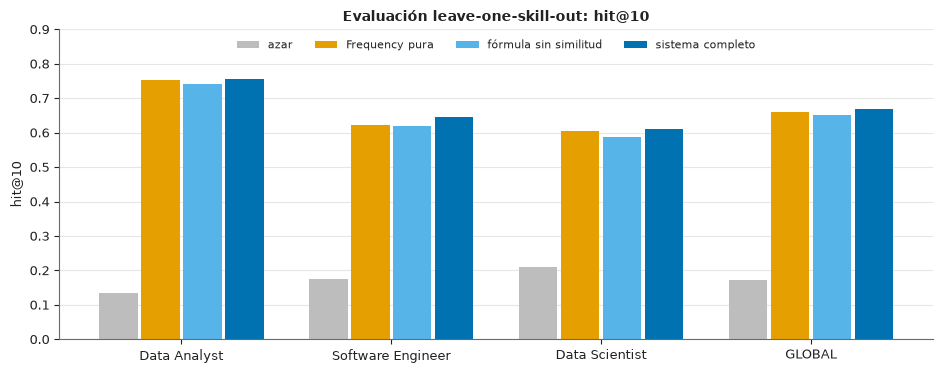

**Lectura.** El sistema completo es muy superior al azar (hit@10 global 0.670 frente a 0.173), pero **no supera claramente a la Frequency pura** (0.660; MRR 0.362 frente a 0.374). La similitud aporta una mejora modesta sobre la fórmula sin ella (hit@10 +0.020). Con 1500 casos, diferencias de un punto están dentro del ruido.

In [28]:
loo = pd.read_csv(REPORTS_DIR / "loo_metrics.csv")
order = ["random", "popularity", "formula_no_similarity", "full"]
labels = {"random": "azar", "popularity": "Frequency pura", "formula_no_similarity": "fórmula sin similitud", "full": "sistema completo"}
view = loo.pivot(index="role", columns="method", values="hit_at_10").loc[["Data Analyst", "Software Engineer", "Data Scientist", "GLOBAL"], order]
display(Markdown("**hit@10 por Role y método** (`reports/loo_metrics.csv`):"))
display(view.rename(columns=labels).round(3))

fig, ax = plt.subplots(figsize=(9.5, 3.8))
x = np.arange(len(view))
width = 0.2
method_colors = {"random": "#bdbdbd", "popularity": "#E69F00", "formula_no_similarity": "#56B4E9", "full": "#0072B2"}
for k, mth in enumerate(order):
    ax.bar(x + (k - 1.5) * width, view[mth].values, width * 0.92, label=labels[mth], color=method_colors[mth])
ax.set_xticks(x)
ax.set_xticklabels(view.index)
ax.set_ylabel("hit@10")
ax.set_ylim(0, 0.9)
ax.set_title("Evaluación leave-one-skill-out: hit@10")
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

g = loo[loo.role == "GLOBAL"].set_index("method")
display(Markdown(
    f"**Lectura.** El sistema completo es muy superior al azar (hit@10 global {g.loc['full','hit_at_10']:.3f} frente a {g.loc['random','hit_at_10']:.3f}), "
    f"pero **no supera claramente a la Frequency pura** ({g.loc['popularity','hit_at_10']:.3f}; MRR {g.loc['full','mrr']:.3f} frente a {g.loc['popularity','mrr']:.3f}). "
    f"La similitud aporta una mejora modesta sobre la fórmula sin ella (hit@10 {g.loc['full','hit_at_10'] - g.loc['formula_no_similarity','hit_at_10']:+.3f}). "
    f"Con {int(g.loc['full','n'])} casos, diferencias de un punto están dentro del ruido."))

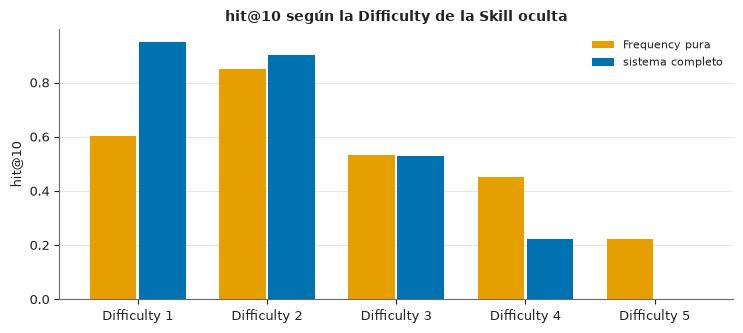

In [29]:
# Por Difficulty de la Skill oculta: el Effort hunde las Skills difíciles (esperable: prioriza lo que conviene aprender primero).
bd = pd.read_csv(REPORTS_DIR / "loo_by_difficulty.csv")
piv = bd.pivot(index="difficulty", columns="method", values="hit_at_10")[["popularity", "full"]]
fig, ax = plt.subplots(figsize=(7.5, 3.4))
x = np.arange(len(piv))
ax.bar(x - 0.19, piv["popularity"], 0.36, color="#E69F00", label="Frequency pura")
ax.bar(x + 0.19, piv["full"], 0.36, color="#0072B2", label="sistema completo")
ax.set_xticks(x)
ax.set_xticklabels([f"Difficulty {d}" for d in piv.index])
ax.set_ylabel("hit@10")
ax.set_title("hit@10 según la Difficulty de la Skill oculta")
ax.legend(frameon=False, fontsize=8)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

### Sesgos medidos (Parte 3)

Las métricas de sesgo miden **qué le muestra el sistema a cada Learner y qué deja fuera**, con 516 Learner profiles por Role (500 derivados de Offers reales y 16 sintéticos) y el top K = 10 de cada Learning path.

In [30]:
conc = pd.read_csv(REPORTS_DIR / "exposure_concentration.csv")
cov = pd.read_csv(REPORTS_DIR / "coverage.csv")
nev = pd.read_csv(REPORTS_DIR / "never_recommended.csv")
corr = pd.read_csv(REPORTS_DIR / "exposure_vs_frequency.csv")
evx = pd.read_csv(REPORTS_DIR / "entry_vs_experienced.csv")
cat_exp = pd.read_csv(REPORTS_DIR / "exposure_by_category.csv")
dif_exp = pd.read_csv(REPORTS_DIR / "exposure_by_difficulty.csv")

sel = lambda df: df[(df.group == "all") & (df.k == 10)].set_index("role")
tab = pd.DataFrame({
    "Top-5 Skills": sel(conc)["top5_share"], "Top-10 Skills": sel(conc)["top10_share"], "Gini": sel(conc)["gini"],
    "Cobertura del Catalog": sel(cov)["coverage"], "Skills mostradas": sel(cov)["skills_shown"],
    "Spearman exposición~Frequency": sel(corr)["spearman"],
}).loc[["Data Analyst", "Software Engineer", "Data Scientist"]]
display(Markdown("**Concentración, cobertura y relación con la Frequency (K = 10, grupo `all`):**"))
display(tab.round(3))

never_global = nev[nev.role == "GLOBAL"]
shares = sel(evx)
display(Markdown(
    f"* **Concentración.** En un Role, 5 de las {len(catalog.CATALOG)} Skills se llevan entre {tab['Top-5 Skills'].min():.0%} y {tab['Top-5 Skills'].max():.0%} de los puestos "
    f"del top 10 y 10 Skills entre {tab['Top-10 Skills'].min():.0%} y {tab['Top-10 Skills'].max():.0%}: la exposición es muy desigual (Gini cercano a {tab['Gini'].mean():.2f}).\n"
    f"* **Cobertura.** Cada Role muestra solo {tab['Cobertura del Catalog'].min():.0%} a {tab['Cobertura del Catalog'].max():.0%} del Catalog, y "
    f"**{len(never_global)} Skills no aparecen en ningún top 10 de ningún Role**: " + ", ".join(f"`{s}`" for s in never_global.skill) + ".\n"
    f"* **La exposición sigue a la Frequency** (Spearman {tab['Spearman exposición~Frequency'].min():.2f} a {tab['Spearman exposición~Frequency'].max():.2f}): el sistema refuerza lo que ya es popular.\n"
    f"* **Nivel inicial frente a con experiencia.** Los Learning paths se parecen mucho (Jaccard@10 de {shares['mean_jaccard'].min():.2f} a {shares['mean_jaccard'].max():.2f}), "
    f"así que el complemento de nivel inicial cambia poco."))

**Concentración, cobertura y relación con la Frequency (K = 10, grupo `all`):**

,Top-5 Skills,Top-10 Skills,Gini,Cobertura del Catalog,Skills mostradas,Spearman exposición~Frequency
role,,,,,,
Data Analyst,0.436,0.763,0.798,0.344,22,0.818
Software Engineer,0.398,0.720,0.773,0.438,28,0.855
Data Scientist,0.405,0.737,0.777,0.438,28,0.758


* **Concentración.** En un Role, 5 de las 64 Skills se llevan entre 40% y 44% de los puestos del top 10 y 10 Skills entre 72% y 76%: la exposición es muy desigual (Gini cercano a 0.78).
* **Cobertura.** Cada Role muestra solo 34% a 44% del Catalog, y **16 Skills no aparecen en ningún top 10 de ningún Role**: `a/b testing`, `airflow`, `algorithms`, `data structures`, `deep learning`, `hadoop`, `kafka`, `looker`, `microservices`, `natural language processing`, `numpy`, `object-oriented programming`, `pytorch`, `scikit-learn`, `tensorflow`, `vba`.
* **La exposición sigue a la Frequency** (Spearman 0.76 a 0.85): el sistema refuerza lo que ya es popular.
* **Nivel inicial frente a con experiencia.** Los Learning paths se parecen mucho (Jaccard@10 de 0.75 a 0.82), así que el complemento de nivel inicial cambia poco.

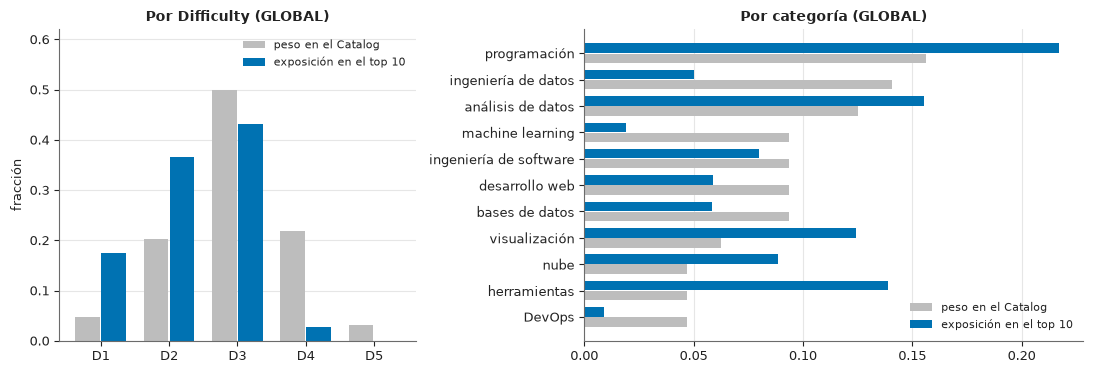

In [31]:
# Exposición por Difficulty (Catalog frente a lo que el sistema muestra) y por categoría (GLOBAL).
d = dif_exp[(dif_exp.role == "GLOBAL") & (dif_exp.group == "all") & (dif_exp.k == 10)].set_index("difficulty")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.4]})
x = np.arange(len(d))
ax1.bar(x - 0.19, d["catalog_share"], 0.36, color="#bdbdbd", label="peso en el Catalog")
ax1.bar(x + 0.19, d["exposure_share"], 0.36, color="#0072B2", label="exposición en el top 10")
ax1.set_xticks(x)
ax1.set_xticklabels([f"D{i}" for i in d.index])
ax1.set_ylabel("fracción")
ax1.set_title("Por Difficulty (GLOBAL)")
ax1.set_ylim(0, 0.62)
ax1.legend(frameon=False, fontsize=8)
ax1.grid(axis="x", visible=False)

c = cat_exp[(cat_exp.role == "GLOBAL") & (cat_exp.group == "all") & (cat_exp.k == 10)].set_index("category")
c = c.sort_values("catalog_share")
y = np.arange(len(c))
ax2.barh(y - 0.19, c["catalog_share"], 0.36, color="#bdbdbd", label="peso en el Catalog")
ax2.barh(y + 0.19, c["exposure_share"], 0.36, color="#0072B2", label="exposición en el top 10")
ax2.set_yticks(y)
ax2.set_yticklabels(c.index)
ax2.set_title("Por categoría (GLOBAL)")
ax2.legend(frameon=False, fontsize=8)
ax2.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Qué significa.** Las Skills de Difficulty 4-5 casi no se exponen aunque son parte del Catalog, y algunas categorías (por ejemplo machine learning) reciben mucho menos que su peso en el Catalog: el Effort las empuja al final. Es coherente con el diseño ("primero lo alcanzable") pero es un sesgo que hay que declarar. Otros sesgos de origen, descritos en `docs/evaluation.md` y `docs/entry-level-complement.md`: Offers en inglés y de EE. UU., Roles asignados por el dataset de origen (no por el título), muestras de nivel inicial pequeñas y juicio experto en Difficulty y Prerequisites. Detalle completo y mitigaciones en [`docs/evaluation.md`](../docs/evaluation.md).

## 9. Limitaciones, cómo ejecutar la app y qué sigue

### Limitaciones principales

* **Difficulty y Prerequisites son juicio experto**, no dato observado: cambiar un valor cambia el orden.
* **Frequency mide qué aparece en las Offers**, no qué le conviene a una persona; y proviene de LinkedIn en inglés, mayormente EE. UU.
* **El Role de cada Offer es el dataset de origen** (no se reclasificó por título), así que un Role puede mezclar Offers de perfiles parecidos.
* **Complemento de nivel inicial con muestras pequeñas** y detección por diccionario en el texto (no es lo mismo que `job_skills`).
* **Similitud con documentos muy cortos** (64 Skills, ~150 palabras): el IDF es ruidoso y las Skills muy frecuentes elevan la similitud de fondo entre Skills de datos. Los pesos (Mastery level, repeticiones, 8 vecinos) son decisiones razonables, no ajustadas con datos.
* **Sin evaluación con Learners reales**: la evaluación es offline (leave-one-skill-out) y no supera claramente a la Frequency pura.
* Sin filtrado colaborativo: no se dispone de interacciones de Learners reales.

### Cómo ejecutar la app web

```bash
source .venv/bin/activate
streamlit run app/streamlit_app.py
```

La app usa el mismo paquete `skillpath` que este cuaderno: formulario de Learner profile (Role, Skills conocidas con Mastery level, intereses, nivel de experiencia), Learning path con explicación y vista del Skill gap.

### Qué sigue

* Revisión humana final del Catalog (`reviewed`) y de las expectativas de los Learner profiles de prueba.
* Estrategias de mitigación de sesgo para la Parte 3 (por ejemplo, sugerir Skills de nicho o de alta Difficulty de forma explícita).
* Incorporar interacciones reales de Learners (filtrado colaborativo) cuando existan.

**Fuentes de los datos:** ver la tabla de la sección 1 (asaniczka como base, arshkon como complemento de nivel inicial). Documentación detallada en `docs/` y `catalog/README.md`.